# Data Visualization Hasil Praktikum Mahasiswa Teknik Informatika

Notebook ini digunakan untuk melihat pola dari data hasil praktikum setelah melalui tahap *data cleansing*. Analisis dibuat menggunakan **Pandas** untuk mengolah data dan **Matplotlib** untuk membuat grafik.

**Fokus analisis:** sebaran nilai, perubahan nilai per bulan, perbandingan mata praktikum, kehadiran, status praktikum, jumlah percobaan, serta hubungan sederhana antara durasi dan nilai.

## Tujuan

1. Membaca file `dataset_bersih.csv` hasil Data Cleansing.
2. Memeriksa struktur dan kualitas data sebelum visualisasi.
3. Menyiapkan kolom tanggal, nilai, durasi, dan jumlah percobaan untuk analisis.
4. Membuat kolom turunan **Bulan Praktikum** dan merangkum data dengan `groupby()`.
5. Membuat grafik dengan judul, label sumbu, ukuran figure, grid, marker, serta anotasi.
6. Menyusun kesimpulan berdasarkan hasil angka dan grafik yang dihasilkan oleh dataset.

## Daftar isi

1. Import library dan pengaturan grafik
2. Membaca dataset hasil cleansing
3. Pemeriksaan struktur dan kualitas data
4. Persiapan kolom untuk visualisasi
5. Visualisasi nilai kosong
6. Distribusi nilai praktikum
7. Agregasi bulanan menggunakan `groupby()`
8. Tren rata-rata nilai per bulan (line chart)
9. Jumlah catatan praktikum per bulan
10. Rata-rata nilai per mata praktikum
11. Distribusi status kelulusan
12. Distribusi kehadiran
13. Distribusi status praktikum
14. Distribusi jumlah percobaan
15. Rata-rata nilai berdasarkan jumlah percobaan
16. Hubungan durasi praktikum dan nilai (scatter plot)
17. Sebaran durasi berdasarkan status kelulusan (boxplot)
18. Sepuluh modul dengan catatan terbanyak
19. Ringkasan otomatis dan penyimpanan hasil

**Cara menggunakan:** jalankan sel dari atas sampai bawah. Bila file `dataset_bersih.csv` tidak berada di folder Drive yang ditentukan, notebook akan meminta mengunggah CSV tersebut.

## 1. Import library dan pengaturan grafik

Pandas digunakan untuk membaca, memilih, dan merangkum data. Matplotlib digunakan untuk membuat grafik. Pengaturan grafik dibuat sederhana supaya judul, label, dan angka mudah dibaca.

In [85]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Ukuran dan tulisan grafik dibuat konsisten.
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["xtick.labelsize"] = 9
plt.rcParams["ytick.labelsize"] = 9

print("Library berhasil diimpor.")

Library berhasil diimpor.


## 2. Membaca dataset hasil cleansing

Notebook ini menggunakan file **`dataset_bersih.csv`**. Secara default, file dicari di folder Google Drive `DataVisualization2418019`. Jika file tidak ditemukan, kamu dapat mengunggah CSV langsung dari komputer.

In [86]:
# Hubungkan Google Drive jika notebook dijalankan di Google Colab.
IN_COLAB = False
try:
    from google.colab import drive, files
    IN_COLAB = True
    drive.mount("/content/drive")
except ImportError:
    files = None
    print("Google Colab tidak terdeteksi. Notebook akan mencari CSV di folder kerja.")

if IN_COLAB:
    BASE_DIR = "/content/drive/MyDrive/DataVisualization2418019"
else:
    BASE_DIR = os.getcwd()

CSV_PATH = os.path.join(BASE_DIR, "dataset_bersih.csv")

if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
    sumber_data = CSV_PATH
else:
    if IN_COLAB:
        print("File dataset_bersih.csv tidak ditemukan di folder yang ditentukan.")
        print("Silakan pilih file CSV hasil Data Cleansing.")
        uploaded = files.upload()
        daftar_csv = [nama for nama in uploaded.keys() if nama.lower().endswith(".csv")]
        if not daftar_csv:
            raise FileNotFoundError("Tidak ada file CSV yang diunggah. Unggah dataset_bersih.csv.")
        nama_file = next((nama for nama in daftar_csv if "dataset_bersih" in nama.lower()), daftar_csv[0])
        df = pd.read_csv(nama_file, encoding="utf-8-sig")
        sumber_data = nama_file
    else:
        raise FileNotFoundError(
            "File dataset_bersih.csv tidak ditemukan. Letakkan file tersebut di folder kerja "
            "atau jalankan notebook ini di Colab dan unggah CSV ketika diminta."
        )

print("Sumber data:", sumber_data)
print("Ukuran dataset:", df.shape[0], "baris dan", df.shape[1], "kolom")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Sumber data: /content/drive/MyDrive/DataVisualization2418019/dataset_bersih.csv
Ukuran dataset: 2996 baris dan 12 kolom


## 3. Pemeriksaan struktur dan kualitas data

Pemeriksaan dilakukan sebelum membuat grafik supaya kita tahu jumlah baris, jumlah kolom, nilai kosong, dan baris duplikat. Pemeriksaan ini hanya membaca data, tidak menghapus atau mengubah data sumber.

In [87]:
print("Nama kolom:")
print(df.columns.tolist())

print("\nTipe data setiap kolom:")
df.info()

print("\nJumlah nilai kosong per kolom:")
display(df.isna().sum().sort_values(ascending=False).to_frame("Jumlah Kosong"))

print("Jumlah baris duplikat identik:", int(df.duplicated().sum()))

# Tampilkan beberapa kolom yang relevan untuk visualisasi.
kolom_pratinjau = [
    "ID Praktikum", "Mata Praktikum", "Modul", "Tanggal Praktikum",
    "Nilai", "Kehadiran", "Durasi Praktikum (Menit)",
    "Jumlah Percobaan", "Status Praktikum", "Status Kelulusan"
]
kolom_pratinjau = [kolom for kolom in kolom_pratinjau if kolom in df.columns]
display(df[kolom_pratinjau].head())

Nama kolom:
['ID Praktikum', 'NIM', 'Nama Mahasiswa', 'Mata Praktikum', 'Modul', 'Tanggal Praktikum', 'Nilai', 'Kehadiran', 'Durasi Praktikum (Menit)', 'Jumlah Percobaan', 'Status Praktikum', 'Status Kelulusan']

Tipe data setiap kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2996 entries, 0 to 2995
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID Praktikum              2996 non-null   object 
 1   NIM                       2996 non-null   int64  
 2   Nama Mahasiswa            2996 non-null   object 
 3   Mata Praktikum            2996 non-null   object 
 4   Modul                     2996 non-null   object 
 5   Tanggal Praktikum         2931 non-null   object 
 6   Nilai                     2996 non-null   float64
 7   Kehadiran                 2996 non-null   object 
 8   Durasi Praktikum (Menit)  2996 non-null   int64  
 9   Jumlah Percobaan          2996 non-null   int6

,Jumlah Kosong
Tanggal Praktikum,65
ID Praktikum,0
Nama Mahasiswa,0
NIM,0
Mata Praktikum,0
Modul,0
Nilai,0
Kehadiran,0
Durasi Praktikum (Menit),0
Jumlah Percobaan,0


Jumlah baris duplikat identik: 0


,ID Praktikum,Mata Praktikum,Modul,Tanggal Praktikum,Nilai,Kehadiran,Durasi Praktikum (Menit),Jumlah Percobaan,Status Praktikum,Status Kelulusan
0,PRA001,Algoritma dan Pemrograman,Percabangan,2026-02-05,87.0,Alpha,120,2,Belum Selesai,Lulus
1,PRA002,Sistem Multimedia,Pengolahan Audio,2026-02-08,61.0,Izin,100,2,Belum Selesai,Remedial
2,PRA003,Object Oriented Programming,Polymorphism,2026-02-11,95.0,Alpha,96,3,Belum Selesai,Lulus
3,PRA004,Basis Data,Join,2026-02-14,78.0,Izin,105,1,Belum Selesai,Lulus
4,PRA005,Pemrograman Web,Rest Api,2026-02-17,71.0,Alpha,90,1,Remedial,Lulus


## 4. Persiapan kolom untuk visualisasi

Tanggal dibaca dengan format `YYYY-MM-DD`, mengikuti format hasil Data Cleansing. Tanggal yang kosong tetap kosong dan tidak diisi dengan tanggal perkiraan. Karena itu, **grafik bulanan hanya menggunakan catatan yang memiliki tanggal valid**. Nilai, durasi, dan jumlah percobaan dikonversi ke numerik agar bisa dihitung dan digambarkan.

In [88]:
# Periksa kolom yang dibutuhkan sebelum membuat grafik.
kolom_wajib = [
    "ID Praktikum", "Mata Praktikum", "Modul", "Tanggal Praktikum",
    "Nilai", "Kehadiran", "Durasi Praktikum (Menit)",
    "Jumlah Percobaan", "Status Praktikum", "Status Kelulusan"
]
kolom_hilang = [kolom for kolom in kolom_wajib if kolom not in df.columns]
if kolom_hilang:
    raise KeyError("Kolom berikut tidak ditemukan: " + ", ".join(kolom_hilang))

# Gunakan salinan khusus analisis; data sumber tidak ditimpa.
df_viz = df.copy()
df_viz["Tanggal Praktikum"] = df_viz["Tanggal Praktikum"].replace(r"^\s*$", np.nan, regex=True)
df_viz["Tanggal_dt"] = pd.to_datetime(
    df_viz["Tanggal Praktikum"], format="%Y-%m-%d", errors="coerce"
)

for kolom in ["Nilai", "Durasi Praktikum (Menit)", "Jumlah Percobaan"]:
    df_viz[kolom] = pd.to_numeric(df_viz[kolom], errors="coerce")

# Kolom turunan untuk merangkum data menurut bulan.
df_viz["Bulan Praktikum"] = df_viz["Tanggal_dt"].dt.to_period("M")

# Buat folder untuk menyimpan grafik dan tabel hasil.
if IN_COLAB:
    OUTPUT_DIR = os.path.join(BASE_DIR, "Hasil Visualisasi")
else:
    OUTPUT_DIR = os.path.join(os.getcwd(), "Hasil_Visualisasi_Praktikum")
GRAFIK_DIR = os.path.join(OUTPUT_DIR, "Grafik")
os.makedirs(GRAFIK_DIR, exist_ok=True)

def simpan_grafik(fig, nama_file):
    """Simpan grafik agar bisa digunakan dalam laporan."""
    fig.savefig(os.path.join(GRAFIK_DIR, nama_file), dpi=200, bbox_inches="tight")

print("Baris data:", len(df_viz))
print("Tanggal valid:", int(df_viz["Tanggal_dt"].notna().sum()))
print("Tanggal kosong/tidak terbaca:", int(df_viz["Tanggal_dt"].isna().sum()))
print("Nilai valid:", int(df_viz["Nilai"].notna().sum()))
print("Durasi valid:", int(df_viz["Durasi Praktikum (Menit)"].notna().sum()))
print("Jumlah percobaan valid:", int(df_viz["Jumlah Percobaan"].notna().sum()))
print("Folder output grafik:", GRAFIK_DIR)

Baris data: 2996
Tanggal valid: 2931
Tanggal kosong/tidak terbaca: 65
Nilai valid: 2996
Durasi valid: 2996
Jumlah percobaan valid: 2996
Folder output grafik: /content/drive/MyDrive/DataVisualization2418019/Hasil Visualisasi/Grafik


### Ringkasan singkat kondisi data

Tabel di bawah membantu membedakan **missing value yang benar-benar kosong** dari kategori teks seperti `Tidak Diisi`. `Tidak Diisi` adalah isi sel berupa teks, sehingga tidak terhitung sebagai missing value oleh Pandas.

In [89]:
ringkasan_kualitas = pd.DataFrame({
    "Pemeriksaan": [
        "Jumlah baris",
        "Jumlah kolom",
        "Jumlah ID Praktikum unik",
        "Jumlah duplikat identik",
        "Jumlah missing value pada file",
        "Tanggal valid",
        "Tanggal kosong/tidak terbaca",
        "Kategori kehadiran 'Tidak Diisi'"
    ],
    "Hasil": [
        len(df_viz),
        len(df_viz.columns),
        df_viz["ID Praktikum"].nunique(),
        int(df_viz.duplicated().sum()),
        int(df.isna().sum().sum()),
        int(df_viz["Tanggal_dt"].notna().sum()),
        int(df_viz["Tanggal_dt"].isna().sum()),
        int((df_viz["Kehadiran"].astype(str).str.strip() == "Tidak Diisi").sum())
    ]
})
display(ringkasan_kualitas)

,Pemeriksaan,Hasil
0,Jumlah baris,2996
1,Jumlah kolom,14
2,Jumlah ID Praktikum unik,2996
3,Jumlah duplikat identik,0
4,Jumlah missing value pada file,65
5,Tanggal valid,2931
6,Tanggal kosong/tidak terbaca,65
7,Kategori kehadiran 'Tidak Diisi',66


## 5. Visualisasi nilai kosong

Grafik ini menunjukkan kolom mana yang masih memiliki nilai kosong. Pada dataset ini, tanggal yang tidak diketahui memang dipertahankan kosong. Nilai kosong pada tanggal tidak dimasukkan ke grafik bulanan.

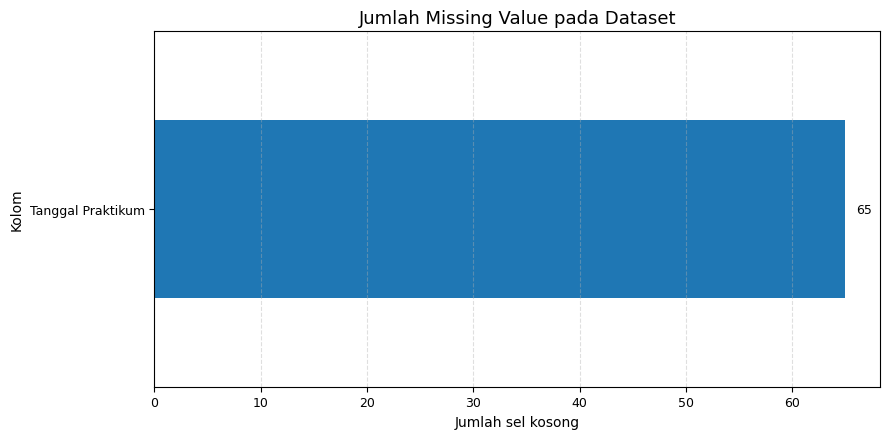

Catatan: teks 'Tidak Diisi' merupakan kategori teks, bukan sel kosong.


In [90]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values()

if not missing.empty:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    missing.plot(kind="barh", ax=ax)
    ax.set_title("Jumlah Missing Value pada Dataset")
    ax.set_xlabel("Jumlah sel kosong")
    ax.set_ylabel("Kolom")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    for bar in ax.patches:
        ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                f"{int(bar.get_width())}", va="center", fontsize=9)
    plt.tight_layout()
    simpan_grafik(fig, "01_missing_value.png")
    plt.show()
else:
    print("Tidak ada missing value pada file.")

print("Catatan: teks 'Tidak Diisi' merupakan kategori teks, bukan sel kosong.")

## 6. Distribusi nilai praktikum

Histogram mengelompokkan nilai ke dalam beberapa rentang sehingga kita bisa melihat di rentang mana nilai paling banyak terkumpul. Garis putus-putus menandai rata-rata nilai.

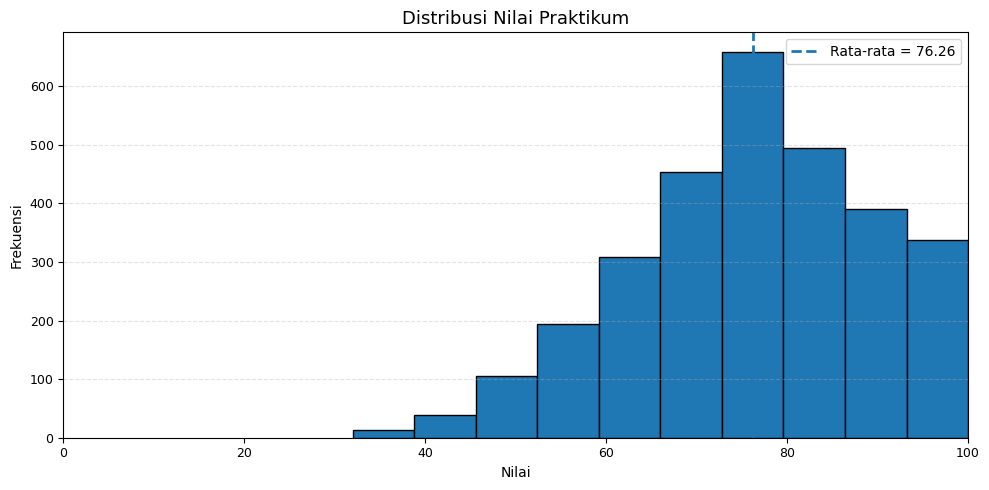

Jumlah nilai yang dianalisis: 2996
Rata-rata: 76.26
Median: 77.0
Nilai minimum: 32.0
Nilai maksimum: 100.0


In [91]:
nilai_valid = df_viz["Nilai"].dropna()

if not nilai_valid.empty:
    rata_rata_nilai = nilai_valid.mean()
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(nilai_valid, bins=10, edgecolor="black")
    ax.axvline(rata_rata_nilai, linestyle="--", linewidth=2,
               label=f"Rata-rata = {rata_rata_nilai:.2f}")
    ax.set_title("Distribusi Nilai Praktikum")
    ax.set_xlabel("Nilai")
    ax.set_ylabel("Frekuensi")
    ax.set_xlim(0, 100)
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.legend()
    plt.tight_layout()
    simpan_grafik(fig, "02_distribusi_nilai.png")
    plt.show()

    print("Jumlah nilai yang dianalisis:", len(nilai_valid))
    print("Rata-rata:", round(nilai_valid.mean(), 2))
    print("Median:", round(nilai_valid.median(), 2))
    print("Nilai minimum:", round(nilai_valid.min(), 2))
    print("Nilai maksimum:", round(nilai_valid.max(), 2))
else:
    print("Tidak ada nilai numerik yang dapat dianalisis.")

## 7. Agregasi bulanan menggunakan `groupby()`

Di dataset praktikum, langkahnya: kita membuat kolom `Bulan Praktikum`, kemudian menghitung **rata-rata nilai**, **jumlah catatan**, dan **rata-rata durasi** setiap bulan.

In [92]:
data_tanggal_valid = df_viz.dropna(subset=["Bulan Praktikum"]).copy()

agregasi_bulanan = (
    data_tanggal_valid.groupby("Bulan Praktikum")
    .agg(
        JumlahCatatan=("ID Praktikum", "count"),
        RataRataNilai=("Nilai", "mean"),
        RataRataDurasi=("Durasi Praktikum (Menit)", "mean")
    )
    .reset_index()
    .sort_values("Bulan Praktikum")
)

# Bulan dibuat menjadi teks agar tabel mudah dibaca.
agregasi_bulanan_tampil = agregasi_bulanan.copy()
agregasi_bulanan_tampil["Bulan Praktikum"] = agregasi_bulanan_tampil["Bulan Praktikum"].astype(str)
agregasi_bulanan_tampil[["RataRataNilai", "RataRataDurasi"]] = (
    agregasi_bulanan_tampil[["RataRataNilai", "RataRataDurasi"]].round(2)
)
display(agregasi_bulanan_tampil)
print("Total catatan yang memiliki tanggal valid:", len(data_tanggal_valid))
print("Catatan tanpa tanggal valid yang tidak masuk agregasi bulanan:", int(df_viz["Bulan Praktikum"].isna().sum()))

,Bulan Praktikum,JumlahCatatan,RataRataNilai,RataRataDurasi
0,2026-02,303,76.61,95.65
1,2026-03,335,75.56,91.22
2,2026-04,332,75.42,90.25
3,2026-05,320,75.69,92.70
4,2026-06,318,77.48,91.73
5,2026-07,345,76.27,92.85
6,2026-08,338,75.77,90.98
7,2026-09,328,77.76,91.30
8,2026-10,312,75.29,92.22


Total catatan yang memiliki tanggal valid: 2931
Catatan tanpa tanggal valid yang tidak masuk agregasi bulanan: 65


## 8. Tren rata-rata nilai per bulan (line chart)

Grafik garis sesuai untuk melihat perubahan nilai dari bulan ke bulan. Ukuran figure, judul, label sumbu, marker, grid, dan anotasi.

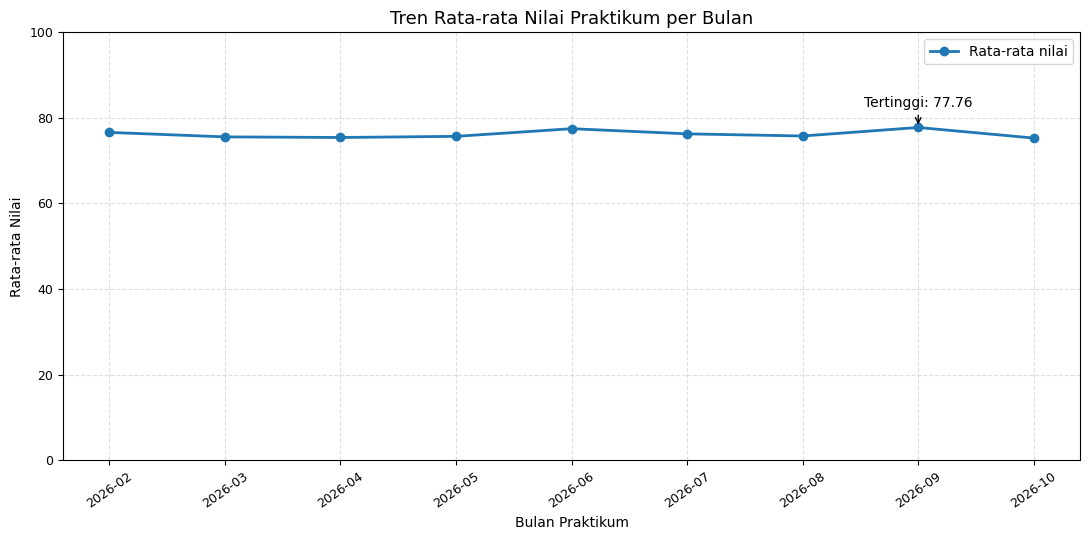

Bulan dengan rata-rata nilai tertinggi: 2026-09
Rata-rata nilai pada bulan tersebut: 77.76


In [93]:
if not agregasi_bulanan.empty and agregasi_bulanan["RataRataNilai"].notna().any():
    plot_bulan = agregasi_bulanan.dropna(subset=["RataRataNilai"]).copy()
    label_bulan = plot_bulan["Bulan Praktikum"].astype(str).tolist()
    nilai_bulan = plot_bulan["RataRataNilai"].to_numpy()

    fig, ax = plt.subplots(figsize=(11, 5.5))
    ax.plot(label_bulan, nilai_bulan, marker="o", linewidth=2,
            linestyle="-", label="Rata-rata nilai")
    ax.set_title("Tren Rata-rata Nilai Praktikum per Bulan")
    ax.set_xlabel("Bulan Praktikum")
    ax.set_ylabel("Rata-rata Nilai")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend()

    # Tandai bulan dengan rata-rata nilai tertinggi.
    posisi_tertinggi = int(np.argmax(nilai_bulan))
    ax.annotate(
        f"Tertinggi: {nilai_bulan[posisi_tertinggi]:.2f}",
        xy=(posisi_tertinggi, nilai_bulan[posisi_tertinggi]),
        xytext=(0, 15), textcoords="offset points", ha="center",
        arrowprops={"arrowstyle": "->"}
    )
    plt.tight_layout()
    simpan_grafik(fig, "03_tren_rata_rata_nilai_bulanan.png")
    plt.show()

    print("Bulan dengan rata-rata nilai tertinggi:", label_bulan[posisi_tertinggi])
    print("Rata-rata nilai pada bulan tersebut:", round(float(nilai_bulan[posisi_tertinggi]), 2))
else:
    print("Tidak cukup tanggal dan nilai valid untuk membuat grafik bulanan.")

## 9. Jumlah catatan praktikum per bulan

Grafik ini melengkapi grafik tren nilai. Jumlah catatan per bulan dapat berubah karena volume data yang tercatat tidak selalu sama. Catatan dengan tanggal kosong tidak dapat ditentukan bulannya, jadi tidak ikut dihitung di grafik ini.

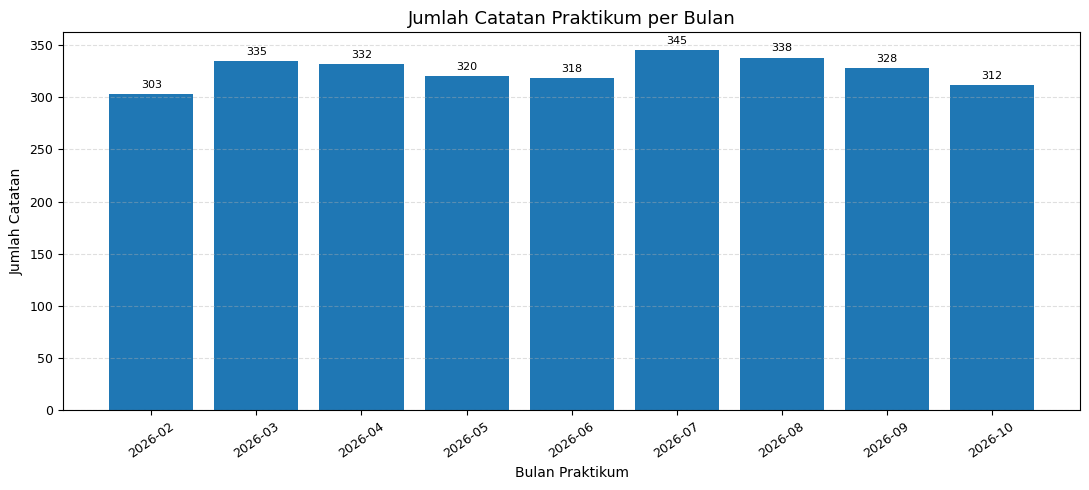

Jumlah catatan bulanan paling banyak: 345
Jumlah catatan bulanan paling sedikit: 303


In [94]:
if not agregasi_bulanan.empty:
    x_bulan = agregasi_bulanan["Bulan Praktikum"].astype(str)
    jumlah_catatan = agregasi_bulanan["JumlahCatatan"]

    fig, ax = plt.subplots(figsize=(11, 5))
    bars = ax.bar(x_bulan, jumlah_catatan)
    ax.set_title("Jumlah Catatan Praktikum per Bulan")
    ax.set_xlabel("Bulan Praktikum")
    ax.set_ylabel("Jumlah Catatan")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.bar_label(bars, padding=3, fontsize=8)
    plt.tight_layout()
    simpan_grafik(fig, "04_jumlah_catatan_per_bulan.png")
    plt.show()

    print("Jumlah catatan bulanan paling banyak:", int(jumlah_catatan.max()))
    print("Jumlah catatan bulanan paling sedikit:", int(jumlah_catatan.min()))
else:
    print("Agregasi bulanan belum tersedia.")

## 10. Rata-rata nilai per mata praktikum

Diagram batang horizontal memudahkan perbandingan 12 mata praktikum. Label `n` menunjukkan jumlah nilai yang digunakan untuk menghitung rata-rata pada masing-masing mata praktikum. Perbedaan rata-rata tidak otomatis berarti satu mata praktikum lebih mudah atau lebih sulit.

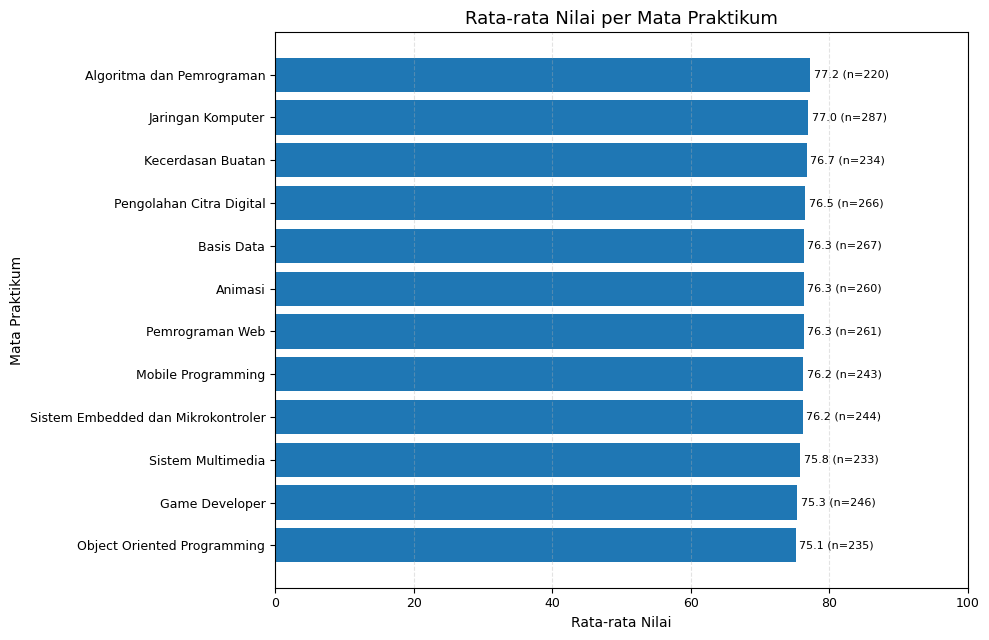

,RataRataNilai,JumlahNilai
Mata Praktikum,,
Algoritma dan Pemrograman,77.21,220
Jaringan Komputer,76.96,287
Kecerdasan Buatan,76.70,234
Pengolahan Citra Digital,76.52,266
Basis Data,76.31,267
Animasi,76.31,260
Pemrograman Web,76.28,261
Mobile Programming,76.23,243
Sistem Embedded dan Mikrokontroler,76.17,244


In [95]:
rata_mata = (
    df_viz.dropna(subset=["Nilai", "Mata Praktikum"])
    .groupby("Mata Praktikum")
    .agg(RataRataNilai=("Nilai", "mean"), JumlahNilai=("Nilai", "count"))
    .sort_values("RataRataNilai", ascending=True)
)

if not rata_mata.empty:
    fig, ax = plt.subplots(figsize=(10, 6.5))
    bars = ax.barh(rata_mata.index, rata_mata["RataRataNilai"])
    ax.set_title("Rata-rata Nilai per Mata Praktikum")
    ax.set_xlabel("Rata-rata Nilai")
    ax.set_ylabel("Mata Praktikum")
    ax.set_xlim(0, 100)
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    for bar, (_, row) in zip(bars, rata_mata.iterrows()):
        ax.text(row["RataRataNilai"] + 0.5, bar.get_y() + bar.get_height()/2,
                f"{row['RataRataNilai']:.1f} (n={int(row['JumlahNilai'])})",
                va="center", fontsize=8)
    plt.tight_layout()
    simpan_grafik(fig, "05_rata_rata_nilai_per_mata_praktikum.png")
    plt.show()
    display(rata_mata.sort_values("RataRataNilai", ascending=False).round(2))
else:
    print("Data nilai dan mata praktikum belum cukup untuk dibandingkan.")

## 11. Distribusi status kelulusan

Grafik ini membandingkan banyaknya catatan pada setiap kategori status kelulusan. Angka menunjukkan jumlah catatan, bukan jumlah mahasiswa unik. Definisi status kelulusan mengikuti nilai kategori yang tersedia di dataset.

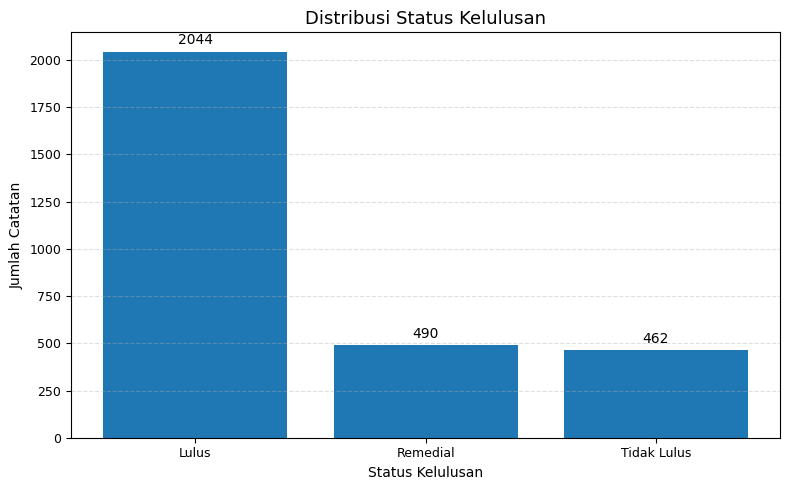

,Jumlah Catatan,Persentase (%)
Status Kelulusan,,
Lulus,2044,68.22
Remedial,490,16.36
Tidak Lulus,462,15.42


In [96]:
kelulusan_counts = df_viz["Status Kelulusan"].fillna("Tidak Diisi").astype(str).value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(kelulusan_counts.index, kelulusan_counts.values)
ax.set_title("Distribusi Status Kelulusan")
ax.set_xlabel("Status Kelulusan")
ax.set_ylabel("Jumlah Catatan")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.bar_label(bars, padding=3)
plt.tight_layout()
simpan_grafik(fig, "06_distribusi_status_kelulusan.png")
plt.show()

kelulusan_tabel = kelulusan_counts.rename_axis("Status Kelulusan").to_frame("Jumlah Catatan")
kelulusan_tabel["Persentase (%)"] = (kelulusan_tabel["Jumlah Catatan"] / len(df_viz) * 100).round(2)
display(kelulusan_tabel)

## 12. Distribusi kehadiran

Grafik batang menunjukkan banyaknya catatan untuk setiap kategori kehadiran. Kategori `Tidak Diisi` ditampilkan apa adanya sebagai penanda bahwa informasi kehadiran tidak diisi pada sumber data.

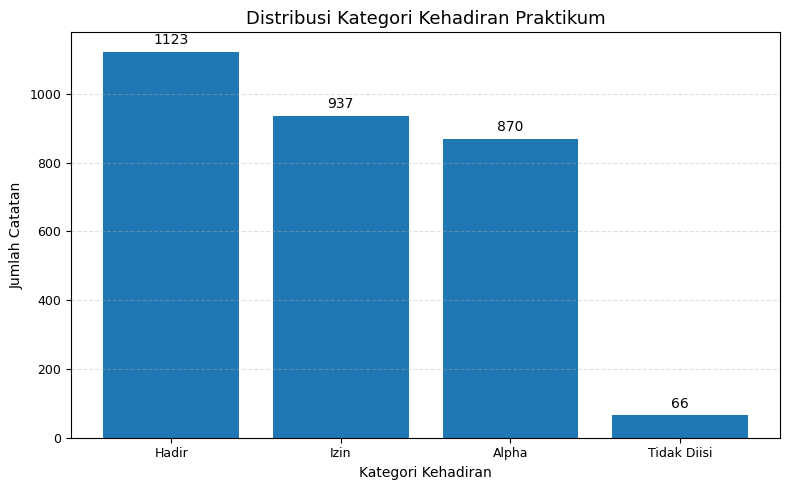

,Jumlah Catatan
Kehadiran,
Hadir,1123
Izin,937
Alpha,870
Tidak Diisi,66


In [97]:
kehadiran_counts = df_viz["Kehadiran"].fillna("Tidak Diisi").astype(str).value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(kehadiran_counts.index, kehadiran_counts.values)
ax.set_title("Distribusi Kategori Kehadiran Praktikum")
ax.set_xlabel("Kategori Kehadiran")
ax.set_ylabel("Jumlah Catatan")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.bar_label(bars, padding=3)
plt.tight_layout()
simpan_grafik(fig, "07_distribusi_kehadiran.png")
plt.show()

display(kehadiran_counts.rename_axis("Kehadiran").to_frame("Jumlah Catatan"))

## 13. Distribusi status praktikum

Status praktikum berbeda dari status kelulusan. Grafik berikut menampilkan banyaknya catatan yang tercatat sebagai Selesai, Belum Selesai, atau kategori status lainnya.

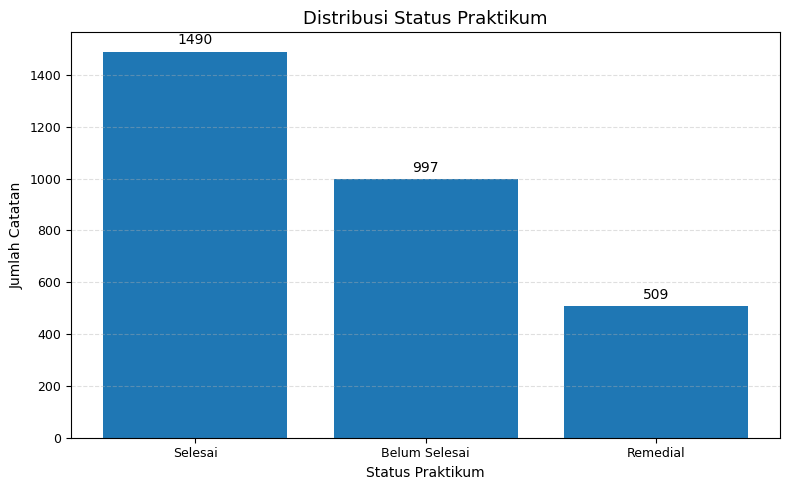

,Jumlah Catatan
Status Praktikum,
Selesai,1490
Belum Selesai,997
Remedial,509


In [98]:
status_praktikum_counts = df_viz["Status Praktikum"].fillna("Tidak Diisi").astype(str).value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(status_praktikum_counts.index, status_praktikum_counts.values)
ax.set_title("Distribusi Status Praktikum")
ax.set_xlabel("Status Praktikum")
ax.set_ylabel("Jumlah Catatan")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.bar_label(bars, padding=3)
plt.tight_layout()
simpan_grafik(fig, "08_distribusi_status_praktikum.png")
plt.show()

display(status_praktikum_counts.rename_axis("Status Praktikum").to_frame("Jumlah Catatan"))

## 14. Distribusi jumlah percobaan

Grafik ini menunjukkan jumlah catatan menurut banyaknya percobaan. Nilai jumlah percobaan tetap diperlakukan sebagai angka, nilai yang tidak valid atau kosong tidak diubah menjadi nol.

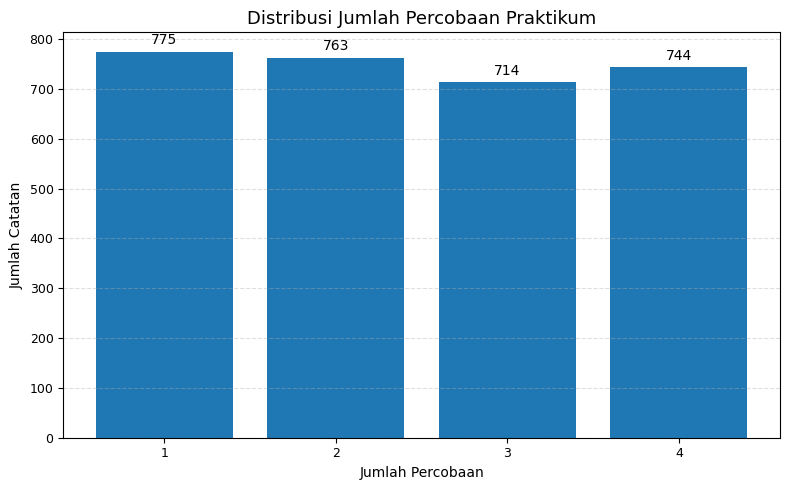

,Jumlah Catatan
Jumlah Percobaan,
1,775
2,763
3,714
4,744


In [99]:
percobaan_valid = df_viz["Jumlah Percobaan"].dropna().astype(int)
percobaan_counts = percobaan_valid.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(percobaan_counts.index.astype(str), percobaan_counts.values)
ax.set_title("Distribusi Jumlah Percobaan Praktikum")
ax.set_xlabel("Jumlah Percobaan")
ax.set_ylabel("Jumlah Catatan")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.bar_label(bars, padding=3)
plt.tight_layout()
simpan_grafik(fig, "09_distribusi_jumlah_percobaan.png")
plt.show()

display(percobaan_counts.rename_axis("Jumlah Percobaan").to_frame("Jumlah Catatan"))

## 15. Rata-rata nilai berdasarkan jumlah percobaan

Grafik ini melihat apakah rata-rata nilai berbeda pada kelompok jumlah percobaan yang berbeda. Ini adalah perbandingan deskriptif. Grafik saja tidak cukup untuk menyimpulkan bahwa jumlah percobaan menyebabkan nilai menjadi lebih tinggi atau rendah.

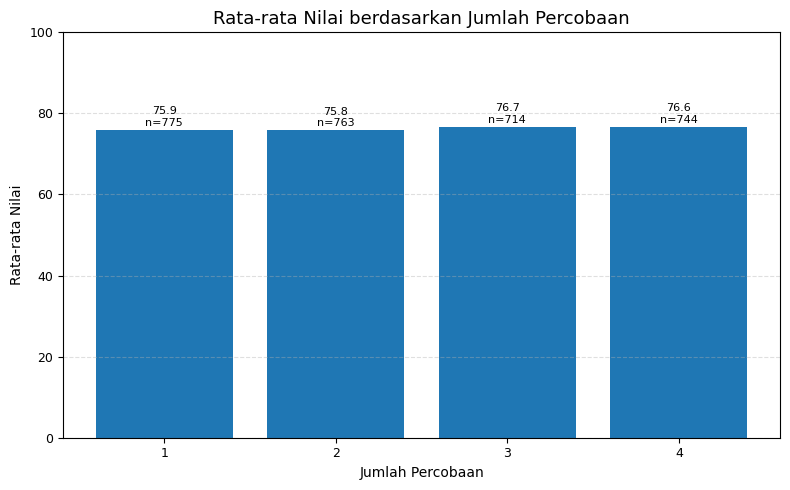

,RataRataNilai,JumlahNilai
Jumlah Percobaan,,
1,75.91,775
2,75.80,763
3,76.72,714
4,76.64,744


In [100]:
nilai_percobaan = (
    df_viz.dropna(subset=["Jumlah Percobaan", "Nilai"])
    .groupby("Jumlah Percobaan")
    .agg(RataRataNilai=("Nilai", "mean"), JumlahNilai=("Nilai", "count"))
    .sort_index()
)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(nilai_percobaan.index.astype(int).astype(str), nilai_percobaan["RataRataNilai"])
ax.set_title("Rata-rata Nilai berdasarkan Jumlah Percobaan")
ax.set_xlabel("Jumlah Percobaan")
ax.set_ylabel("Rata-rata Nilai")
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.4)
for bar, (_, row) in zip(bars, nilai_percobaan.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f"{row['RataRataNilai']:.1f}\nn={int(row['JumlahNilai'])}",
            ha="center", fontsize=8)
plt.tight_layout()
simpan_grafik(fig, "10_rata_rata_nilai_menurut_percobaan.png")
plt.show()

display(nilai_percobaan.round(2))

## 16. Hubungan durasi praktikum dan nilai (scatter plot)

Scatter plot memperlihatkan sebaran pasangan durasi dan nilai. Nilai korelasi Pearson ikut ditampilkan sebagai ukuran sederhana hubungan linear. Korelasi mendekati nol berarti hubungan linearnya lemah, hal tersebut bukan bukti ada atau tidaknya hubungan sebab-akibat.

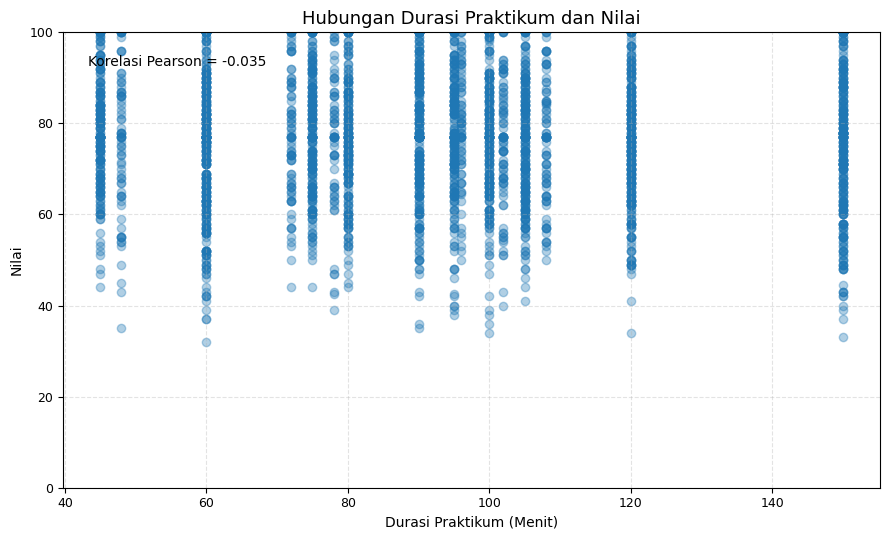

Jumlah catatan yang digunakan: 2996
Korelasi Pearson: -0.035


In [101]:
data_scatter = df_viz.dropna(subset=["Durasi Praktikum (Menit)", "Nilai"]).copy()

if len(data_scatter) >= 2:
    korelasi = data_scatter["Durasi Praktikum (Menit)"].corr(data_scatter["Nilai"])
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.scatter(data_scatter["Durasi Praktikum (Menit)"], data_scatter["Nilai"], alpha=0.35)
    ax.set_title("Hubungan Durasi Praktikum dan Nilai")
    ax.set_xlabel("Durasi Praktikum (Menit)")
    ax.set_ylabel("Nilai")
    ax.set_ylim(0, 100)
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.text(0.03, 0.95, f"Korelasi Pearson = {korelasi:.3f}",
            transform=ax.transAxes, va="top")
    plt.tight_layout()
    simpan_grafik(fig, "11_scatter_durasi_dan_nilai.png")
    plt.show()
    print("Jumlah catatan yang digunakan:", len(data_scatter))
    print("Korelasi Pearson:", round(float(korelasi), 3))
else:
    print("Data belum cukup untuk scatter plot dan korelasi.")

## 17. Sebaran durasi berdasarkan status kelulusan (boxplot)

Boxplot merangkum median, rentang antarkuartil, dan sebaran durasi di tiap status kelulusan. Perbandingan ini digunakan untuk mendeskripsikan data, bukan menyatakan bahwa durasi menentukan kelulusan.

/tmp/ipykernel_403/4212335833.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(values_box, labels=labels_box, showfliers=False)


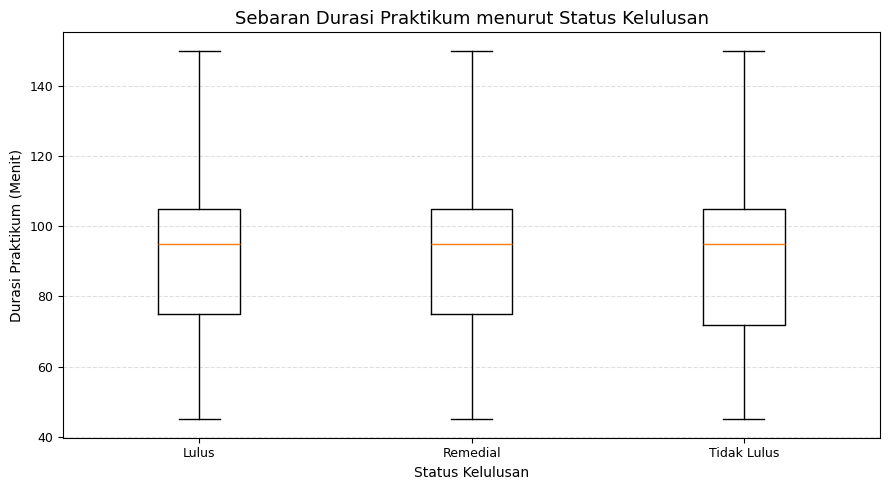

,count,median,mean
Status Kelulusan,,,
Lulus,2044,95.0,91.82
Remedial,490,95.0,92.92
Tidak Lulus,462,95.0,92.15


In [102]:
data_box = df_viz.dropna(subset=["Durasi Praktikum (Menit)", "Status Kelulusan"]).copy()
status_urutan = [s for s in ["Lulus", "Remedial", "Tidak Lulus"] if s in data_box["Status Kelulusan"].astype(str).unique()]
status_urutan += [s for s in data_box["Status Kelulusan"].astype(str).unique() if s not in status_urutan]
data_box_list = [
    data_box.loc[data_box["Status Kelulusan"].astype(str) == status, "Durasi Praktikum (Menit)"].dropna().to_numpy()
    for status in status_urutan
]
data_box_list = [(label, values) for label, values in zip(status_urutan, data_box_list) if len(values) > 0]

if data_box_list:
    labels_box = [item[0] for item in data_box_list]
    values_box = [item[1] for item in data_box_list]
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.boxplot(values_box, labels=labels_box, showfliers=False)
    ax.set_title("Sebaran Durasi Praktikum menurut Status Kelulusan")
    ax.set_xlabel("Status Kelulusan")
    ax.set_ylabel("Durasi Praktikum (Menit)")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    simpan_grafik(fig, "12_boxplot_durasi_menurut_kelulusan.png")
    plt.show()
    display(data_box.groupby("Status Kelulusan")["Durasi Praktikum (Menit)"].agg(["count", "median", "mean"]).round(2))
else:
    print("Data durasi dan status kelulusan belum cukup untuk boxplot.")

## 18. Sepuluh modul dengan catatan terbanyak

Jumlah modul pada dataset cukup banyak. Karena itu, grafik menampilkan sepuluh modul paling sering tercatat agar label tetap terbaca. Kategori `Tidak Diisi` tidak ditampilkan sebagai modul nyata.

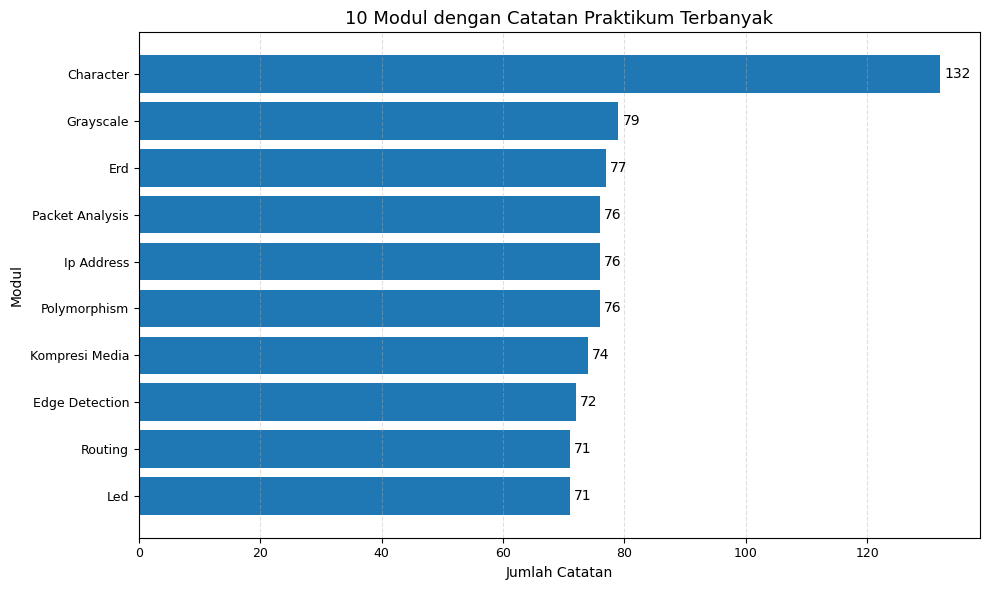

,Jumlah Catatan
Modul,
Character,132
Grayscale,79
Erd,77
Packet Analysis,76
Polymorphism,76
Ip Address,76
Kompresi Media,74
Edge Detection,72
Routing,71


Jumlah catatan yang berkategori 'Tidak Diisi' pada kolom Modul: 94


In [103]:
modul_asli = df_viz["Modul"].dropna().astype(str).str.strip()
modul_asli = modul_asli[(modul_asli != "") & (modul_asli.str.lower() != "tidak diisi")]
modul_counts = modul_asli.value_counts().head(10).sort_values()

if not modul_counts.empty:
    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(modul_counts.index, modul_counts.values)
    ax.set_title("10 Modul dengan Catatan Praktikum Terbanyak")
    ax.set_xlabel("Jumlah Catatan")
    ax.set_ylabel("Modul")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.bar_label(bars, padding=3)
    plt.tight_layout()
    simpan_grafik(fig, "13_top_10_modul.png")
    plt.show()
    display(modul_counts.sort_values(ascending=False).rename_axis("Modul").to_frame("Jumlah Catatan"))
    print("Jumlah catatan yang berkategori 'Tidak Diisi' pada kolom Modul:",
          int((df_viz["Modul"].astype(str).str.strip().str.lower() == "tidak diisi").sum()))
else:
    print("Tidak ada nama modul yang valid untuk ditampilkan.")

## 19. Ringkasan otomatis hasil analisis

Ringkasan berikut dihitung langsung dari data.

In [104]:
print("=" * 58)
print("RINGKASAN DATA VISUALIZATION")
print("=" * 58)
print("Sumber data:", sumber_data)
print("Jumlah baris:", len(df_viz))
print("Jumlah kolom:", len(df.columns))
print("Duplikat identik:", int(df.duplicated().sum()))
print("Tanggal valid:", int(df_viz["Tanggal_dt"].notna().sum()))
print("Tanggal tidak tersedia:", int(df_viz["Tanggal_dt"].isna().sum()))

if df_viz["Nilai"].notna().any():
    print("Rata-rata nilai:", round(float(df_viz["Nilai"].mean()), 2))
    print("Median nilai:", round(float(df_viz["Nilai"].median()), 2))
    print("Nilai terendah:", float(df_viz["Nilai"].min()))
    print("Nilai tertinggi:", float(df_viz["Nilai"].max()))

if not rata_mata.empty:
    tertinggi_mata = rata_mata["RataRataNilai"].idxmax()
    terendah_mata = rata_mata["RataRataNilai"].idxmin()
    print("Rata-rata tertinggi per mata praktikum:", tertinggi_mata,
          "(", round(float(rata_mata.loc[tertinggi_mata, "RataRataNilai"]), 2), ")")
    print("Rata-rata terendah per mata praktikum:", terendah_mata,
          "(", round(float(rata_mata.loc[terendah_mata, "RataRataNilai"]), 2), ")")

if not agregasi_bulanan.empty and agregasi_bulanan["RataRataNilai"].notna().any():
    indeks_bulan_max = agregasi_bulanan["RataRataNilai"].idxmax()
    baris_bulan_max = agregasi_bulanan.loc[indeks_bulan_max]
    print("Rata-rata bulanan tertinggi:", str(baris_bulan_max["Bulan Praktikum"]),
          "(", round(float(baris_bulan_max["RataRataNilai"]), 2), ")")

if not kelulusan_counts.empty:
    print("Status kelulusan terbanyak:", kelulusan_counts.idxmax(), "-", int(kelulusan_counts.max()), "catatan")
if not kehadiran_counts.empty:
    print("Kategori kehadiran terbanyak:", kehadiran_counts.idxmax(), "-", int(kehadiran_counts.max()), "catatan")

if len(data_scatter) >= 2:
    print("Korelasi Pearson durasi dan nilai:", round(float(korelasi), 3))

print("\nCatatan interpretasi:")
print("- Grafik bulanan hanya mencakup catatan yang mempunyai tanggal valid.")
print("- Satu baris adalah satu catatan praktikum, bukan satu mahasiswa unik.")
print("- Pola atau korelasi pada grafik tidak membuktikan sebab-akibat.")

RINGKASAN DATA VISUALIZATION
Sumber data: /content/drive/MyDrive/DataVisualization2418019/dataset_bersih.csv
Jumlah baris: 2996
Jumlah kolom: 12
Duplikat identik: 0
Tanggal valid: 2931
Tanggal tidak tersedia: 65
Rata-rata nilai: 76.26
Median nilai: 77.0
Nilai terendah: 32.0
Nilai tertinggi: 100.0
Rata-rata tertinggi per mata praktikum: Algoritma dan Pemrograman ( 77.21 )
Rata-rata terendah per mata praktikum: Object Oriented Programming ( 75.14 )
Rata-rata bulanan tertinggi: 2026-09 ( 77.76 )
Status kelulusan terbanyak: Lulus - 2044 catatan
Kategori kehadiran terbanyak: Hadir - 1123 catatan
Korelasi Pearson durasi dan nilai: -0.035

Catatan interpretasi:
- Grafik bulanan hanya mencakup catatan yang mempunyai tanggal valid.
- Satu baris adalah satu catatan praktikum, bukan satu mahasiswa unik.
- Pola atau korelasi pada grafik tidak membuktikan sebab-akibat.


## 20. Menyimpan tabel ringkasan dan grafik

Grafik disimpan sebagai file PNG dan tabel agregasi disimpan sebagai CSV di folder hasil visualisasi. File tersebut dapat dipakai saat membuat laporan.

In [105]:
# Simpan tabel utama.
agregasi_simpan = agregasi_bulanan.copy()
agregasi_simpan["Bulan Praktikum"] = agregasi_simpan["Bulan Praktikum"].astype(str)
agregasi_simpan.to_csv(os.path.join(OUTPUT_DIR, "agregasi_bulanan.csv"), index=False, encoding="utf-8-sig")

rata_mata.to_csv(os.path.join(OUTPUT_DIR, "rata_rata_nilai_per_mata_praktikum.csv"), encoding="utf-8-sig")
kelulusan_tabel.to_csv(os.path.join(OUTPUT_DIR, "distribusi_status_kelulusan.csv"), encoding="utf-8-sig")
kehadiran_counts.rename_axis("Kehadiran").to_frame("Jumlah Catatan").to_csv(
    os.path.join(OUTPUT_DIR, "distribusi_kehadiran.csv"), encoding="utf-8-sig"
)

print("Tabel ringkasan disimpan di:", OUTPUT_DIR)
print("Grafik PNG disimpan di:", GRAFIK_DIR)
print("Jumlah file grafik:", len([nama for nama in os.listdir(GRAFIK_DIR) if nama.lower().endswith(".png")]))
print("Selesai. Periksa folder output sebelum mengumpulkan tugas.")

Tabel ringkasan disimpan di: /content/drive/MyDrive/DataVisualization2418019/Hasil Visualisasi
Grafik PNG disimpan di: /content/drive/MyDrive/DataVisualization2418019/Hasil Visualisasi/Grafik
Jumlah file grafik: 13
Selesai. Periksa folder output sebelum mengumpulkan tugas.
